# CNN-Based Classification of Images Containing One Person or Multiple People

**Course work – Neural Networks | Comparing CNN architectures**

This VS Code/Jupyter notebook compares six experiments using your **existing local Kaggle dataset**. It does not download COCO images or COCO annotations.

Expected folder structure:

```text
person_image_cnn_project/
├── dataset/
│   ├── train/
│   │   ├── single_person/
│   │   └── multiple_people/
│   ├── validation/
│   │   ├── single_person/
│   │   └── multiple_people/
│   └── test/
│       ├── single_person/
│       └── multiple_people/
├── outputs/
└── src/
    └── Comparison_CNN_Models_Local_Dataset_VSCode.ipynb
```

The notebook uses `single_person` as class `single` (label 0) and `multiple_people` as class `group` (label 1). The dataset's group label means **two or more people**. It does not provide exact people counts or person bounding boxes.


## Step 0 – Setup and settings

In [3]:
import os, json, time, zipfile, random, gc, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests, urllib3
from PIL import Image, ImageOps
from IPython.display import display

import tensorflow as tf

# Let TensorFlow take GPU memory only when needed, so PyTorch (person detector in Step 10) can also use the GPU
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU") or "none (switch runtime to GPU!)")

TensorFlow 2.21.0 | Keras 3.15.1 | GPU: none (switch runtime to GPU!)


In [ ]:
# ---------------- SETTINGS ----------------
QUICK_TEST = False    # Start with True to test quickly; set False for the full comparison
IMG_SIZE = 160
BATCH = 32
EPOCHS = 2 if QUICK_TEST else 10
SEED = 42

MIN_PERSON_FRAC = 0.02  # used only by the optional pretrained person detector in Step 10

# Locate the project root whether VS Code starts the kernel in the root or src/.
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "dataset").is_dir():
    ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").is_dir():
    ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Cannot find a 'dataset' folder. Open the project folder in VS Code, "
        "or place this notebook inside the project's src folder."
    )

DATA_DIR = ROOT / "dataset"
WORK = ROOT / "outputs" / "comparison_notebook"
(WORK / "weights").mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["single", "group"]  # label 0 = single_person; label 1 = multiple_people

random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("Project root:", ROOT)
print("Dataset path:", DATA_DIR)
print("Notebook outputs:", WORK)


Project root: c:\Users\gunel\Downloads\CNN_Person_Classification_Code\person_image_cnn_project
Dataset path: c:\Users\gunel\Downloads\CNN_Person_Classification_Code\person_image_cnn_project\dataset
Notebook outputs: c:\Users\gunel\Downloads\CNN_Person_Classification_Code\person_image_cnn_project\outputs\comparison_notebook


## Step 1 – Load the local dataset

We use the Kaggle images already stored in the project. No COCO annotation ZIP, image downloads, or internet access for dataset preparation is required.

| Class used by this notebook | Source folder | Label |
|---|---|---:|
| `single` | `single_person/` | 0 |
| `group` | `multiple_people/` | 1 |

**Important:** the `multiple_people` class means two or more people. The class label does not tell us the exact number of people or their bounding boxes. The notebook therefore will not claim exact counts from the dataset labels.

The notebook expects pre-existing `train`, `validation`, and `test` folders. Make sure the same image is not present in more than one split; duplicated images can make test scores misleading.


In [ ]:
# COCO download helper removed.
# This notebook reads your local Kaggle dataset from DATA_DIR instead.


In [6]:

# 1a) Index images from the local dataset.
# QUICK_TEST limits image indexing to 150 images per class per split.

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
FOLDER_TO_LABEL = {
    "single_person": ("single", 0),
    "multiple_people": ("group", 1),
}

QUICK_IMAGES_PER_CLASS = 150
rows = []

for split_name in ["train", "validation", "test"]:
    for folder_name, (label_name, y_value) in FOLDER_TO_LABEL.items():
        folder = DATA_DIR / split_name / folder_name

        if not folder.is_dir():
            raise FileNotFoundError(f"Required folder is missing: {folder}")

        image_paths = sorted(
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        )

        if not image_paths:
            raise ValueError(f"No images found in {folder}")

        # Sample paths BEFORE opening the images.
        if QUICK_TEST:
            rng = random.Random(
                f"{SEED}_{split_name}_{folder_name}"
            )
            image_paths = rng.sample(
                image_paths,
                min(QUICK_IMAGES_PER_CLASS, len(image_paths))
            )

        print(f"{split_name}/{folder_name}: indexing {len(image_paths)} images")

        for image_path in image_paths:
            try:
                with Image.open(image_path) as im:
                    width, height = im.size
                    im.verify()

                rows.append({
                    "image_id": image_path.stem,
                    "path": str(image_path.resolve()),
                    "width": width,
                    "height": height,
                    "label": label_name,
                    "y": y_value,
                    "split": split_name,
                    "n_people": 1 if label_name == "single" else 2,
                    "person_size": np.nan,
                })

            except Exception as exc:
                print(f"Skipping unreadable image: {image_path} ({exc})")

df = pd.DataFrame(rows)

if df.empty:
    raise ValueError("No readable images were found.")

candidates = df.copy()

print("\nImages indexed:", len(df))
print("\nClass counts:")
print(df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0))


train/single_person: indexing 150 images
train/multiple_people: indexing 150 images
validation/single_person: indexing 150 images
validation/multiple_people: indexing 150 images
test/single_person: indexing 150 images
test/multiple_people: indexing 150 images

Images indexed: 900

Class counts:
label
single    450
group     450
Name: count, dtype: int64


In [7]:
# 1b) Local images are already present; no downloads are required.
print("Using local dataset files. No download step is needed.")
print("Supported image formats:", ", ".join(sorted(EXTENSIONS)))


Using local dataset files. No download step is needed.
Supported image formats: .bmp, .jpeg, .jpg, .png, .webp


In [8]:

# 1c) Use existing splits and sample a balanced subset for quick testing.

train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df = df[df["split"] == "validation"].copy().reset_index(drop=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

if QUICK_TEST:
    QUICK_IMAGES_PER_CLASS = 150

    def sample_split(frame):
        parts = []
        for label in CLASS_NAMES:
            group = frame[frame["label"] == label]
            n = min(QUICK_IMAGES_PER_CLASS, len(group))
            parts.append(group.sample(n=n, random_state=SEED))
        return pd.concat(parts, ignore_index=True)

    train_df = sample_split(train_df)
    val_df = sample_split(val_df)
    test_df = sample_split(test_df)

    print("QUICK TEST enabled: up to 150 images per class per split.")
else:
    print("Full dataset enabled.")

# Recombine sampled splits while preserving their split labels.
df = pd.concat([train_df, val_df, test_df], ignore_index=True)

split_table = pd.crosstab(df["split"], df["label"])
split_table = split_table.reindex(
    index=["train", "validation", "test"],
    columns=CLASS_NAMES,
    fill_value=0
)
split_table["total"] = split_table.sum(axis=1)

print(split_table)

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("One of the dataset splits is empty.")


QUICK TEST enabled: up to 150 images per class per split.
label       single  group  total
split                           
train          150    150    300
validation     150    150    300
test           150    150    300


## Step 2 – Look at the data
Class balance, image resolutions, people per image and some examples. Write your comments about these plots in the report.

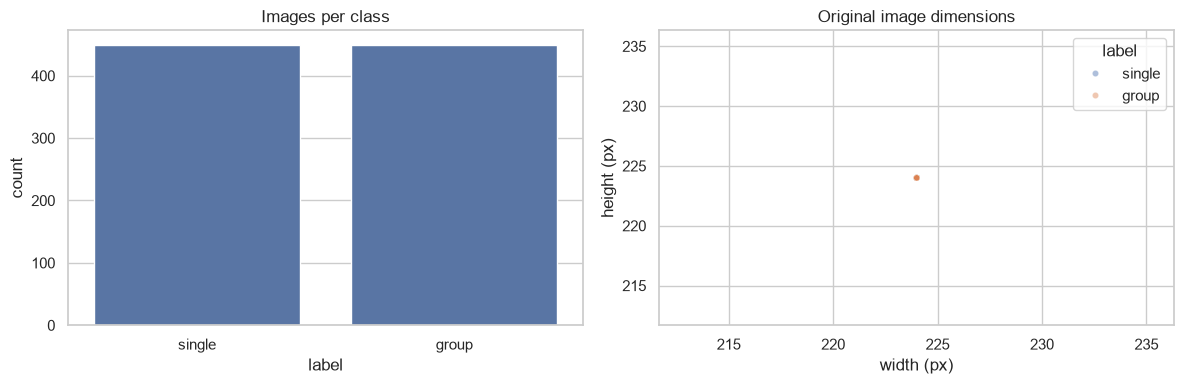


Image counts by split and class:
label       single  group  total
split                           
train          150    150    300
validation     150    150    300
test           150    150    300

Note: the dataset has class labels only; exact group counts and person sizes are not available.


In [9]:
# Inspect class balance and original image resolutions.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="label", order=CLASS_NAMES, ax=ax[0])
ax[0].set_title("Images per class")
sns.scatterplot(data=df, x="width", y="height", hue="label", alpha=.45, s=20, ax=ax[1])
ax[1].set_title("Original image dimensions")
ax[1].set_xlabel("width (px)")
ax[1].set_ylabel("height (px)")
plt.tight_layout()
plt.show()

print("\nImage counts by split and class:")
print(split_table)
print("\nNote: the dataset has class labels only; exact group counts and person sizes are not available.")


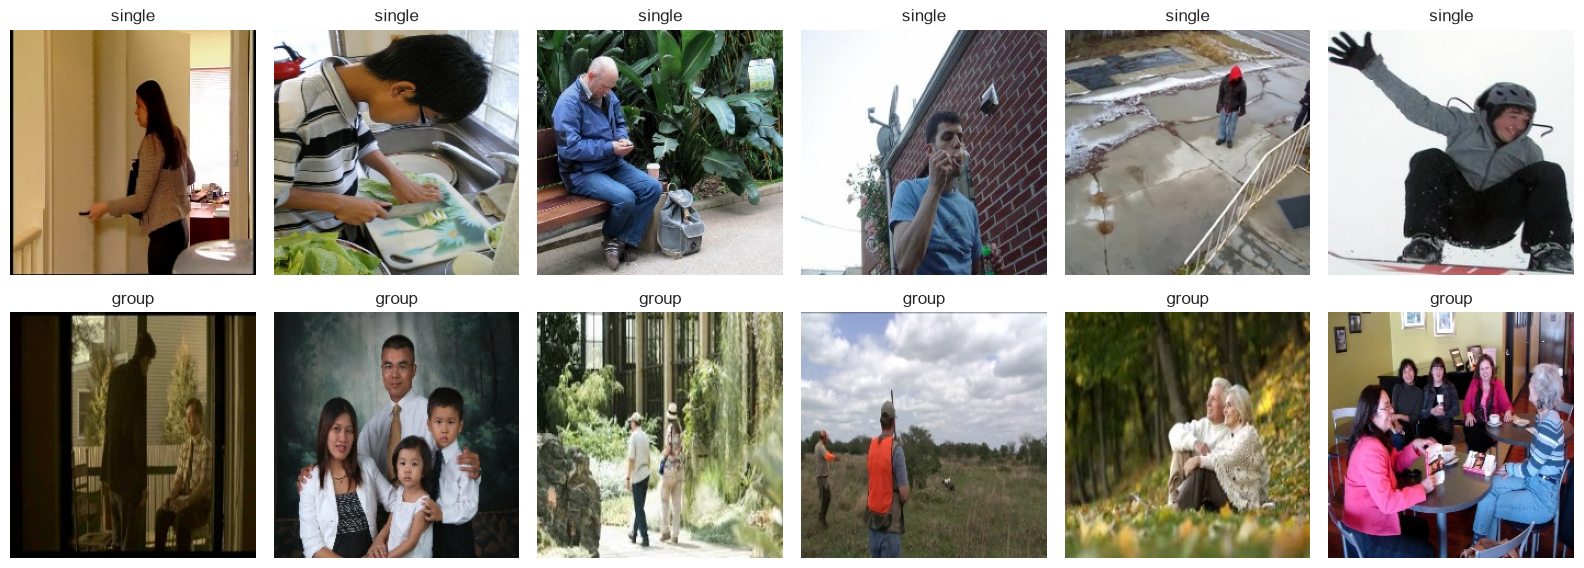

In [10]:
# Example images from each class
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for row, cls in enumerate(CLASS_NAMES):
    subset = df[df.label == cls]
    sample_rows = subset.sample(min(6, len(subset)), random_state=1)
    for col, r in enumerate(sample_rows.itertuples()):
        axes[row, col].imshow(Image.open(r.path).convert("RGB"))
        axes[row, col].set_title(cls)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()


## Step 3 – Preprocessing and augmentation
* **Resize** every image to 160 × 160 pixels (all networks need the same input size).
* **Normalise** the pixel values – done inside each model, because each network expects a different range.
* **Augmentation** (only during training, optional in the model): random horizontal flip, small rotation, zoom and contrast change. It creates "new" training images and reduces over-fitting.

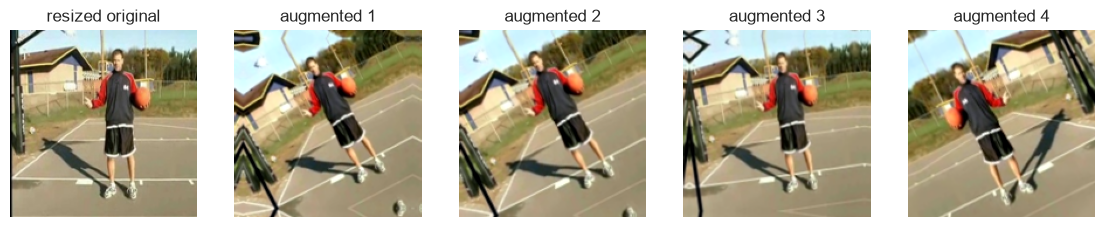

In [11]:
def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(tf.clip_by_value(img, 0, 255)), tf.uint8), label

def make_dataset(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values.astype(str), frame.y.values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()      # decode every image only once
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y))
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_dataset(train_df, True), make_dataset(val_df, False), make_dataset(test_df, False)

def make_augmentation():
    # a NEW augmentation block for every model (sharing one block between models causes errors in Keras 3)
    return keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
                             layers.RandomZoom(0.15), layers.RandomContrast(0.2)], name="augmentation")

# show the effect of augmentation on one image
augmentation_demo = make_augmentation()
sample = np.array(Image.open(train_df.path[0]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(sample); axes[0].set_title("resized original")
for i in range(1, 5):
    aug = augmentation_demo(sample[None].astype("float32"), training=True)[0]
    axes[i].imshow(np.clip(np.asarray(aug), 0, 255).astype("uint8"))
    axes[i].set_title(f"augmented {i}")
for a in axes: a.axis("off")
plt.show()

## Step 4 – The three CNN models
| Model | Idea | Parameters |
|---|---|---|
| **Custom CNN** | our own small network: 4 blocks of (Conv → BatchNorm → ReLU) ×2 + MaxPooling | ~1.2 M |
| **ResNet50** | 50 layers with *residual (skip) connections*, very accurate | ~24 M |
| **MobileNetV2** | *depthwise-separable convolutions*, small and fast | ~2.3 M |

ResNet50 and MobileNetV2 can start from **random weights** ("scratch") or from **ImageNet weights** ("pretrained" = transfer learning; here all layers are re-trained with a small learning rate, BatchNorm statistics stay frozen).
All models get the same classification end: *global average pooling → dropout → 1 neuron with sigmoid* (output = probability of "group").

In [12]:
class ResNetPreprocess(layers.Layer):
    # Same as keras.applications.resnet50.preprocess_input ("caffe" mode): RGB -> BGR and subtract the ImageNet mean.
    # Written as a layer so that saving / loading weights works without Lambda-layer problems.
    def call(self, x):
        x = x[..., ::-1]
        return x - tf.constant([103.939, 116.779, 123.68], dtype=x.dtype)

def build_model(arch, pretrained=False, augment=True):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs) if augment else inputs

    if arch == "custom":
        x = layers.Rescaling(1 / 255)(x)                      # pixels 0..255 -> 0..1
        for filters in (32, 64, 128, 256):
            for _ in range(2):
                x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
                x = layers.BatchNormalization()(x)
                x = layers.ReLU()(x)
            x = layers.MaxPooling2D()(x)
    else:
        weights = "imagenet" if pretrained else None
        if arch == "resnet50":
            base = keras.applications.ResNet50(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            x = ResNetPreprocess()(x)
        elif arch == "mobilenetv2":
            base = keras.applications.MobileNetV2(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            x = layers.Rescaling(1 / 127.5, offset=-1)(x)     # pixels -> -1..1
        else:
            raise ValueError(f"unknown architecture {arch}")
        x = base(x, training=False) if pretrained else base(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name=f"{arch}_{'pre' if pretrained else 'scratch'}_{'aug' if augment else 'noaug'}")

build_model("custom").summary()

Model: "custom_scratch_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,175,393 (4.48 MB)

 Trainable params: 1,173,473 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Step 5 – Experiments
Six experiments answer the research questions:

| Experiment | Question it answers |
|---|---|
| CustomCNN_noAug vs. CustomCNN_Aug | Does **data augmentation** help? |
| ResNet50_scratch vs. ResNet50_pretrained | Does **transfer learning** help? |
| MobileNetV2_scratch vs. MobileNetV2_pretrained | Does **transfer learning** help? |
| all models together | Which CNN is best, and at what computational cost? |

Training stops early if the validation loss does not improve for 4 epochs; the best epoch is kept.

In [13]:
EXPERIMENTS = {   # name: (architecture, pretrained, augmentation)
    "CustomCNN_noAug":        ("custom",      False, False),
    "CustomCNN_Aug":          ("custom",      False, True),
    "ResNet50_scratch":       ("resnet50",    False, True),
    "ResNet50_pretrained":    ("resnet50",    True,  True),
    "MobileNetV2_scratch":    ("mobilenetv2", False, True),
    "MobileNetV2_pretrained": ("mobilenetv2", True,  True),
}
RESULTS = {}

def train_and_test(name, arch, pretrained, augment):
    keras.backend.clear_session(); gc.collect(); keras.utils.set_random_seed(SEED)
    model = build_model(arch, pretrained, augment)
    lr = 1e-4 if pretrained else 1e-3            # small learning rate when starting from ImageNet weights
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
    print(f"\n=== {name} ({model.count_params():,} parameters) ===")

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
    train_time = time.time() - start

    model.predict(test_ds.take(1), verbose=0)                       # warm-up
    start = time.time()
    prob = model.predict(test_ds, verbose=0).ravel()                # probability of "group" for every test image
    infer_ms = 1000 * (time.time() - start) / len(test_df)

    model.save_weights(str(WORK / "weights" / f"{name}.weights.h5"))
    RESULTS[name] = dict(history={k: [float(v) for v in vals] for k, vals in history.history.items()},
                         prob=prob, params=model.count_params(),
                         train_min=train_time / 60, infer_ms=infer_ms, epochs=len(history.history["loss"]),
                         config=(arch, pretrained, augment))
    print(f"-> test accuracy {accuracy_score(test_df.y, prob >= .5):.3f}  |  training {train_time / 60:.1f} min")
    del model; gc.collect()

for name, (arch, pretrained, augment) in EXPERIMENTS.items():
    if name in RESULTS:            # already trained (useful if you re-run the cell after a disconnect)
        continue
    train_and_test(name, arch, pretrained, augment)



=== CustomCNN_noAug (1,175,393 parameters) ===
Epoch 1/2
10/10 - 26s - 3s/step - accuracy: 0.5433 - loss: 0.8793 - val_accuracy: 0.5000 - val_loss: 0.7281 - learning_rate: 0.0010
Epoch 2/2
10/10 - 22s - 2s/step - accuracy: 0.6633 - loss: 0.6861 - val_accuracy: 0.5000 - val_loss: 1.0838 - learning_rate: 0.0010
-> test accuracy 0.500  |  training 0.8 min

=== CustomCNN_Aug (1,175,393 parameters) ===
Epoch 1/2
10/10 - 25s - 3s/step - accuracy: 0.4567 - loss: 1.0234 - val_accuracy: 0.5033 - val_loss: 0.6985 - learning_rate: 0.0010
Epoch 2/2
10/10 - 20s - 2s/step - accuracy: 0.5467 - loss: 0.7366 - val_accuracy: 0.5000 - val_loss: 0.7694 - learning_rate: 0.0010
-> test accuracy 0.500  |  training 0.8 min

=== ResNet50_scratch (23,589,761 parameters) ===
Epoch 1/2
10/10 - 77s - 8s/step - accuracy: 0.5500 - loss: 1.7716 - val_accuracy: 0.5000 - val_loss: 62.2536 - learning_rate: 0.0010
Epoch 2/2
10/10 - 35s - 4s/step - accuracy: 0.4933 - loss: 1.0982 - val_accuracy: 0.5000 - val_loss: 319.0

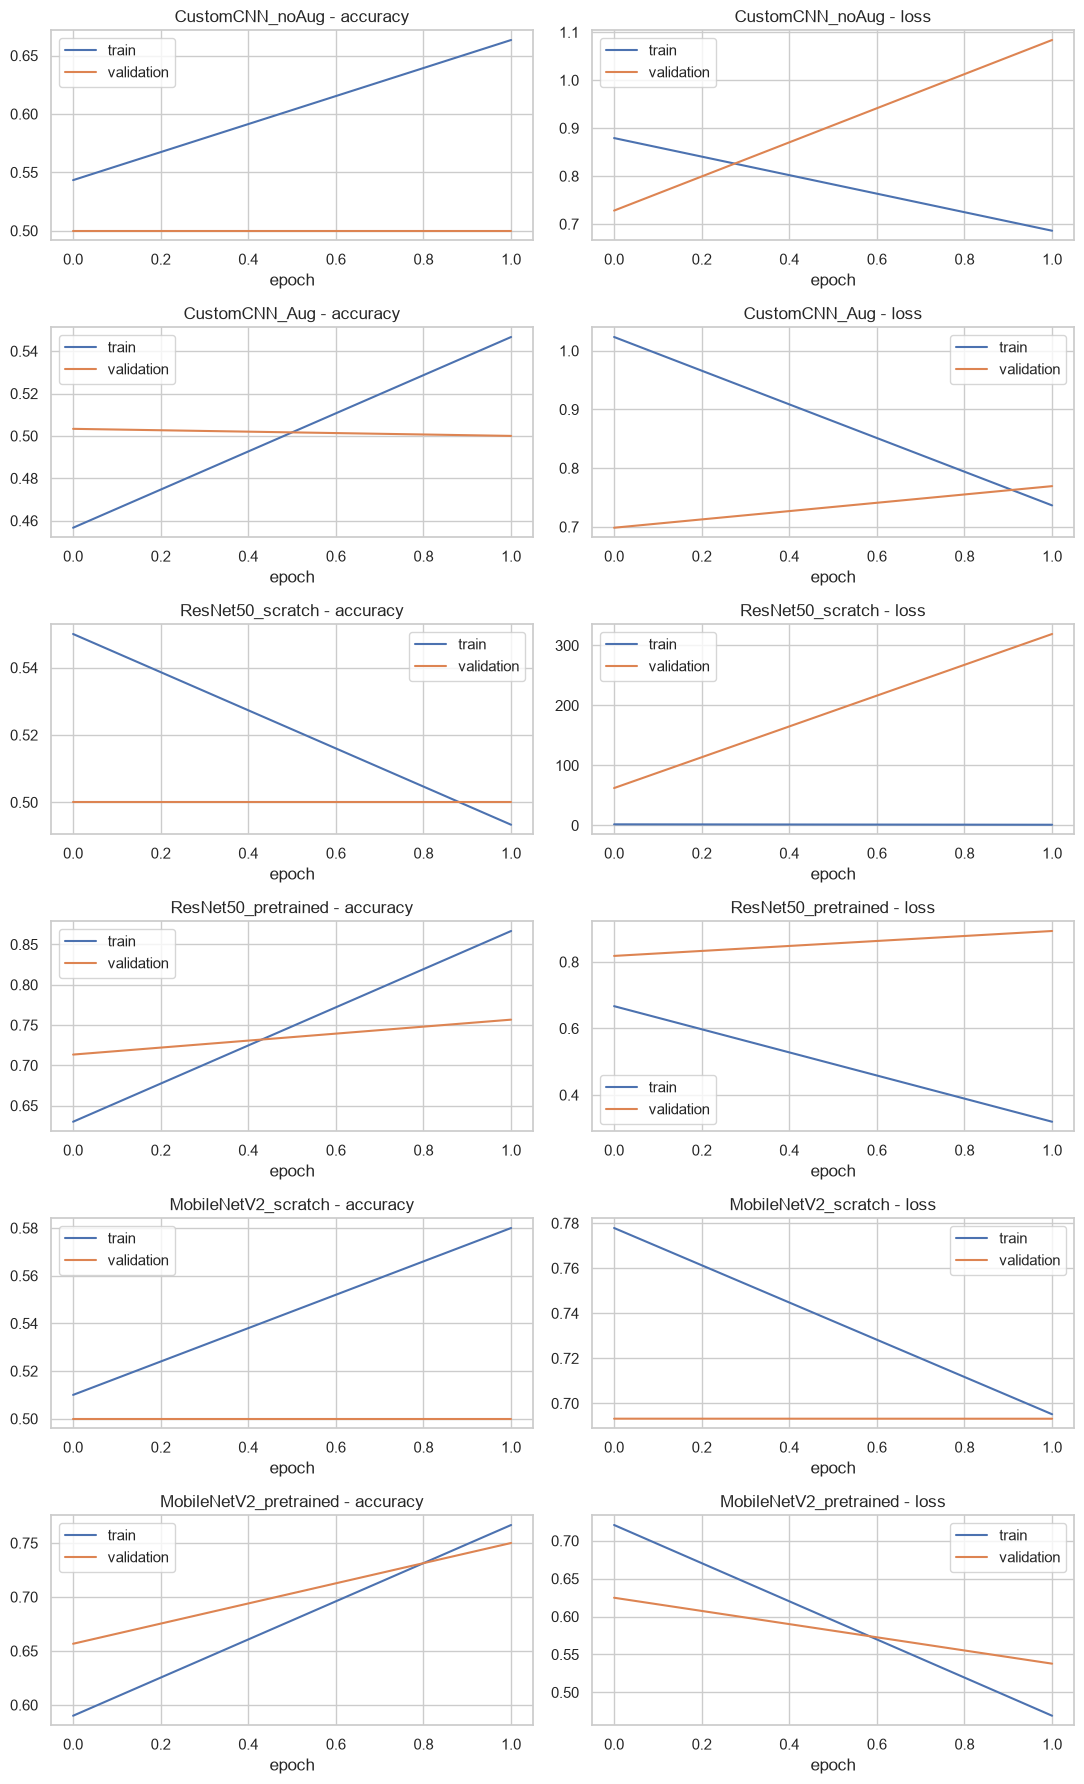

In [14]:
# Training curves: accuracy and loss for every experiment (train vs. validation)
fig, axes = plt.subplots(len(RESULTS), 2, figsize=(11, 3 * len(RESULTS)), squeeze=False)
for row, (name, r) in enumerate(RESULTS.items()):
    h = r["history"]
    axes[row, 0].plot(h["accuracy"], label="train"); axes[row, 0].plot(h["val_accuracy"], label="validation")
    axes[row, 0].set_title(f"{name} - accuracy"); axes[row, 0].set_xlabel("epoch"); axes[row, 0].legend()
    axes[row, 1].plot(h["loss"], label="train"); axes[row, 1].plot(h["val_loss"], label="validation")
    axes[row, 1].set_title(f"{name} - loss"); axes[row, 1].set_xlabel("epoch"); axes[row, 1].legend()
plt.tight_layout(); plt.show()

## Step 6 – Evaluation on the test set
The test images were never used for training or for choosing the best epoch. "Group" is the positive class.

* **Accuracy** – share of correct answers
* **Precision** – of the images called *group*, how many really are groups
* **Recall** – of all real groups, how many were found
* **F1-score** – balance of precision and recall
* **Confusion matrix** – how many images of each true class were predicted as each class

In [15]:
y_true = test_df.y.values.astype(int)
rows = []
for name, r in RESULTS.items():
    pred = (r["prob"] >= 0.5).astype(int)
    rows.append(dict(model=name, accuracy=accuracy_score(y_true, pred),
                     precision=precision_score(y_true, pred, zero_division=0),
                     recall=recall_score(y_true, pred, zero_division=0),
                     f1=f1_score(y_true, pred, zero_division=0)))
metrics = pd.DataFrame(rows).set_index("model").round(3)
display(metrics.style.background_gradient(cmap="Greens").format("{:.3f}"))
metrics.to_csv(WORK / "test_metrics.csv")       # table for the report
best = metrics.f1.idxmax()
print("Best model (highest F1):", best)

,accuracy,precision,recall,f1
model,,,,
CustomCNN_noAug,0.500,0.000,0.000,0.000
CustomCNN_Aug,0.500,0.500,0.007,0.013
ResNet50_scratch,0.500,0.000,0.000,0.000
ResNet50_pretrained,0.730,0.658,0.960,0.780
MobileNetV2_scratch,0.500,0.000,0.000,0.000
MobileNetV2_pretrained,0.780,0.784,0.773,0.779


Best model (highest F1): ResNet50_pretrained


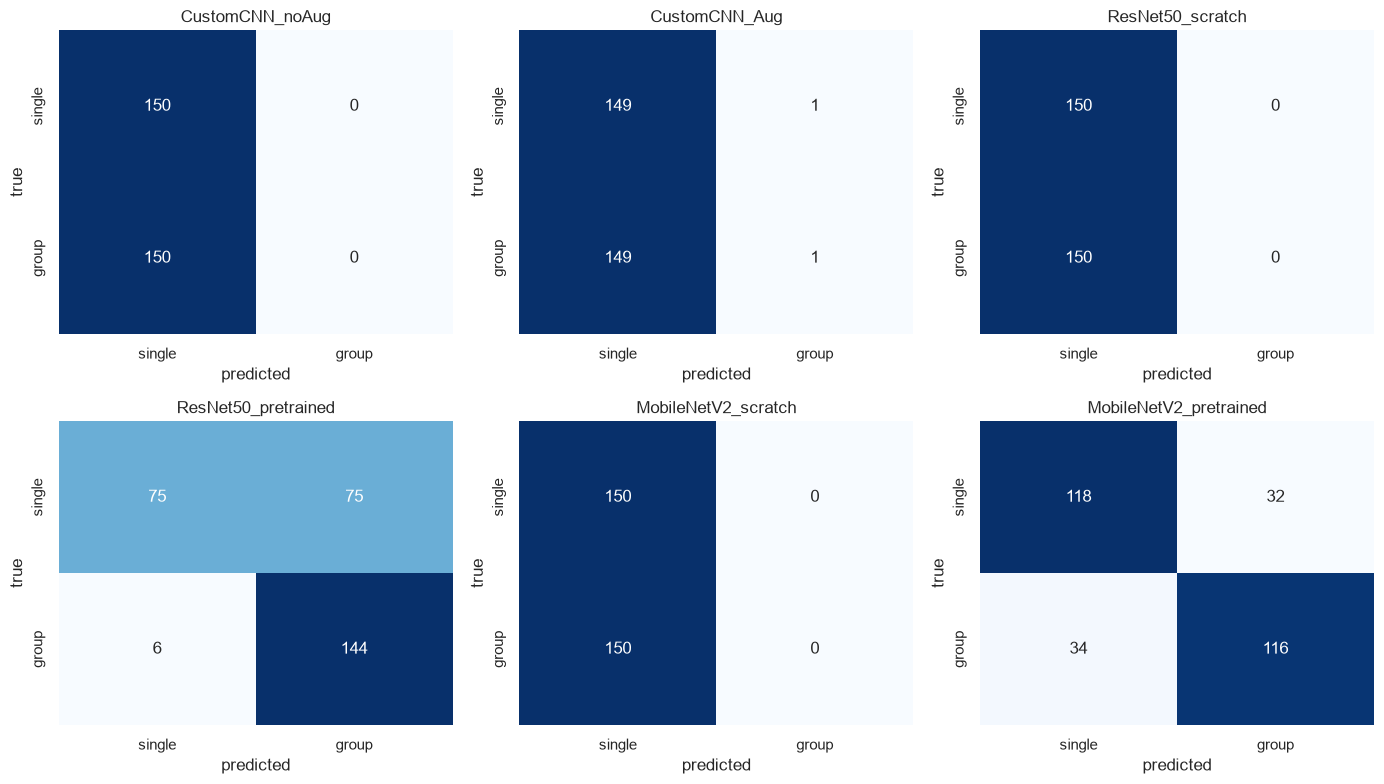

In [16]:
# Confusion matrices of all models
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax in axes.ravel(): ax.axis("off")
for ax, (name, r) in zip(axes.ravel(), RESULTS.items()):
    ax.axis("on")
    cm = confusion_matrix(y_true, (r["prob"] >= .5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## Step 7 – Effect of transfer learning and data augmentation
Difference in F1-score (positive number = the first option is better).

In [17]:
f1 = metrics.f1
effects = pd.DataFrame({
    "comparison": ["Augmentation (custom CNN): with - without",
                   "Transfer learning (ResNet50): pretrained - scratch",
                   "Transfer learning (MobileNetV2): pretrained - scratch"],
    "F1 difference": [f1["CustomCNN_Aug"] - f1["CustomCNN_noAug"],
                      f1["ResNet50_pretrained"] - f1["ResNet50_scratch"],
                      f1["MobileNetV2_pretrained"] - f1["MobileNetV2_scratch"]]}).set_index("comparison").round(3)
display(effects)

# gap between train and validation accuracy in the last epoch (bigger gap = more over-fitting)
gap = pd.Series({n: r["history"]["accuracy"][-1] - r["history"]["val_accuracy"][-1] for n, r in RESULTS.items()},
                name="train - val accuracy (last epoch)").round(3)
display(gap.to_frame())

,F1 difference
comparison,
Augmentation (custom CNN): with - without,0.013
Transfer learning (ResNet50): pretrained - scratch,0.780
Transfer learning (MobileNetV2): pretrained - scratch,0.779


,train - val accuracy (last epoch)
CustomCNN_noAug,0.163
CustomCNN_Aug,0.047
ResNet50_scratch,-0.007
ResNet50_pretrained,0.110
MobileNetV2_scratch,0.080
MobileNetV2_pretrained,0.017


## Step 8 – Computational efficiency
Parameters, training time and prediction speed per image (speed depends on the GPU, but the *differences between models* are what matters).

,parameters_millions,epochs_trained,training_minutes,ms_per_image,f1
CustomCNN_noAug,1.175,2.0,0.806,14.775,0.000
CustomCNN_Aug,1.175,2.0,0.754,14.215,0.013
ResNet50_scratch,23.590,2.0,1.876,34.611,0.000
ResNet50_pretrained,23.590,2.0,1.918,34.322,0.780
MobileNetV2_scratch,2.259,2.0,1.044,16.469,0.000
MobileNetV2_pretrained,2.259,2.0,0.970,11.026,0.779


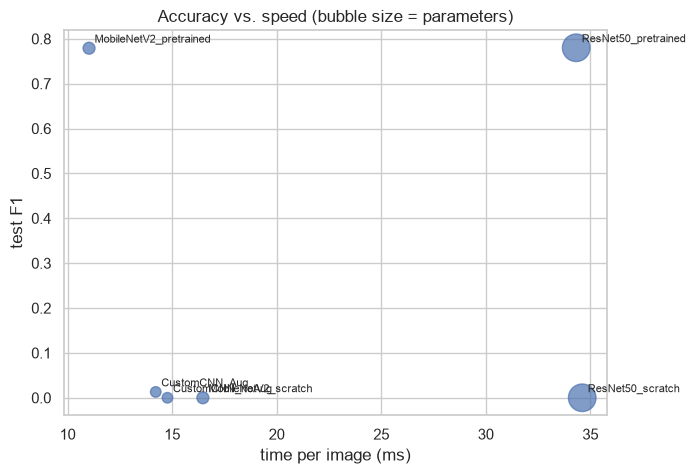

In [18]:
efficiency = pd.DataFrame({n: dict(parameters_millions=r["params"] / 1e6, epochs_trained=r["epochs"],
                                   training_minutes=r["train_min"], ms_per_image=r["infer_ms"], f1=metrics.f1[n])
                           for n, r in RESULTS.items()}).T.astype(float).round(3)
display(efficiency)
efficiency.to_csv(WORK / "efficiency.csv")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(efficiency.ms_per_image, efficiency.f1, s=40 + 15 * efficiency.parameters_millions, alpha=.7)
for n in efficiency.index:
    ax.annotate(n, (efficiency.ms_per_image[n], efficiency.f1[n]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("time per image (ms)"); ax.set_ylabel("test F1"); ax.set_title("Accuracy vs. speed (bubble size = parameters)")
plt.show()

## Step 9 – Misclassified images
We look at the mistakes of the best model and check whether they depend on the number of people.

ResNet50_pretrained: 81 wrong of 300 test images


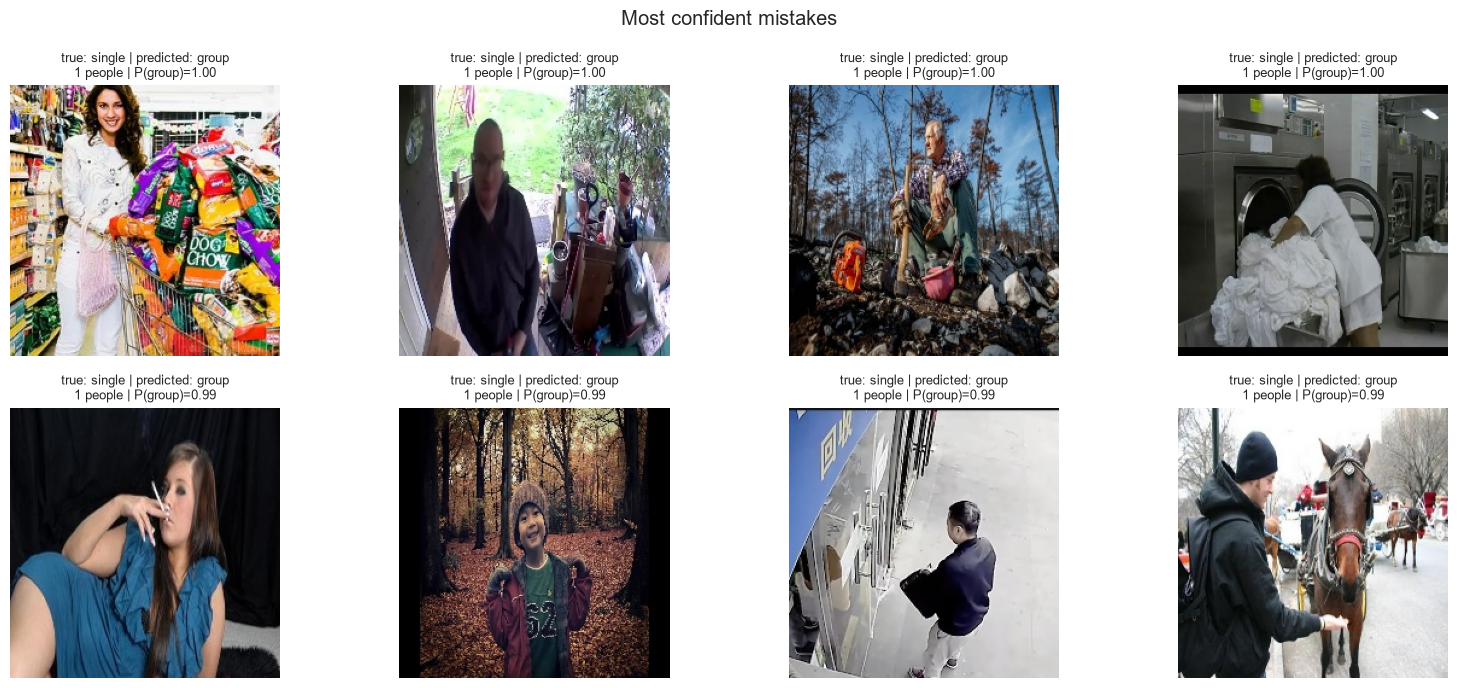

In [19]:
errors = test_df.copy()
errors["prob"] = RESULTS[best]["prob"]
errors["pred"] = (errors.prob >= .5).astype(int)
errors["wrong"] = errors.pred != errors.y
print(f"{best}: {errors.wrong.sum()} wrong of {len(errors)} test images")

wrong_images = (errors[errors.wrong].assign(confidence=lambda d: (d.prob - .5).abs())
                .sort_values("confidence", ascending=False).head(8))
if len(wrong_images) == 0:
    print("No mistakes on the test set!")
else:
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax in axes.ravel(): ax.axis("off")
    for ax, r in zip(axes.ravel(), wrong_images.itertuples()):
        ax.imshow(Image.open(r.path).convert("RGB"))
        ax.set_title(f"true: {CLASS_NAMES[r.y]} | predicted: {CLASS_NAMES[r.pred]}\n{r.n_people} people | P(group)={r.prob:.2f}", fontsize=9)
    plt.suptitle("Most confident mistakes"); plt.tight_layout(); plt.show()

In [20]:
# The dataset provides only two image-level classes, not exact counts or bounding boxes.
# Therefore, error rates by exact number of people or person size cannot be computed reliably.
print("Error rate by true class:")
print(
    errors.groupby("label", observed=True).wrong
    .agg(["mean", "size"])
    .rename(columns={"mean": "error_rate", "size": "images"})
    .assign(error_rate=lambda d: (100 * d["error_rate"]).round(1))
    .to_string()
)
print(
    "\nLimitation: 'multiple_people' means two or more people. "
    "Exact counts and person bounding-box sizes are not present in this dataset."
)


Error rate by true class:
        error_rate  images
label                     
group          4.0     150
single        50.0     150

Limitation: 'multiple_people' means two or more people. Exact counts and person bounding-box sizes are not present in this dataset.


**Possible reasons for errors (check them on your pictures and write the examples in the report):**
small or distant people · people hidden or cut by the image border · one big person in front with others far behind · statues, posters, screens or reflections that look like people · label noise (class-label ambiguity) · the model learns the scene ("street", "party") instead of counting people · low resolution (160 px) makes background people disappear.

## Step 10 – Try your own photo

Run the detector/classifier setup cell, then run the next cell to select image files from your computer. The best CNN from Step 6 predicts `single` or `group`; a pretrained person detector additionally estimates a count and draws bounding boxes.

The detector is a separate pretrained model. Its count can be wrong when people overlap, are small, or are partly hidden. This optional detector does not change the classifier's training results.


In [21]:
# Load the best classifier again (from the saved weights) and a pretrained person detector
import torch, torchvision
from torchvision.ops import nms, box_area
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights

DET_SCORE   = 0.5    # only boxes the detector is quite sure about
DET_NMS_IOU = 0.7    # boxes that overlap a lot are the same person
DET_INSIDE  = 0.95   # a box lying almost completely inside a bigger one is a part of that person (duplicate)

arch, pretrained, augment = RESULTS[best]["config"]
keras.backend.clear_session()
classifier = build_model(arch, pretrained, augment)
classifier.load_weights(str(WORK / "weights" / f"{best}.weights.h5"))
print("Classifier:", best)

device = "cuda" if torch.cuda.is_available() else "cpu"
# ResNet50-FPN v2 detector: slower than the MobileNet one, but it counts people in close groups much more reliably
detector = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT).to(device).eval()
print("Person detector ready on", device)

def count_people(img):
    tensor = torchvision.transforms.functional.to_tensor(img).to(device)
    with torch.no_grad():
        out = detector([tensor])[0]
    keep = (out["labels"] == 1) & (out["scores"] >= DET_SCORE)
    boxes, scores = out["boxes"][keep], out["scores"][keep]
    # 1) remove strongly overlapping duplicates
    k = nms(boxes, scores, DET_NMS_IOU)
    boxes, scores = boxes[k], scores[k]
    # 2) remove boxes that are only a part of another person (e.g. face/upper body inside a full-body box)
    areas = box_area(boxes)
    final = []
    for i in torch.argsort(areas, descending=True).tolist():          # big boxes first
        duplicate = False
        for j in final:
            x1 = torch.max(boxes[i, 0], boxes[j, 0]); y1 = torch.max(boxes[i, 1], boxes[j, 1])
            x2 = torch.min(boxes[i, 2], boxes[j, 2]); y2 = torch.min(boxes[i, 3], boxes[j, 3])
            inter = (x2 - x1).clamp(min=0) * (y2 - y1).clamp(min=0)
            if inter / areas[i] > DET_INSIDE:
                duplicate = True; break
        if not duplicate:
            final.append(i)
    boxes = boxes[final].cpu().numpy()
    # 3) keep only clearly visible people (same rule as in the dataset)
    return [b for b in boxes if (b[2] - b[0]) * (b[3] - b[1]) / (img.width * img.height) >= MIN_PERSON_FRAC]

def predict_photo(path):
    try:
        img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")      # fix rotation of phone photos
    except Exception as e:
        print(f"Cannot open {path}: {e}  (use JPG or PNG)")
        return

    # 1) classification: our CNN (same preprocessing as in training: resize to 160x160, values 0..255)
    x = tf.round(tf.image.resize(np.asarray(img, dtype=np.float32), (IMG_SIZE, IMG_SIZE)))[None]
    p_group = float(classifier.predict(x, verbose=0)[0, 0])
    answer = CLASS_NAMES[int(p_group >= 0.5)].upper()

    # 2) counting: pretrained detector (only people that are clearly visible)
    boxes = count_people(img)

    plt.figure(figsize=(8, 7)); plt.imshow(img); plt.axis("off")
    for b in boxes:
        plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="lime", lw=2))
    plt.title(f"{answer}  (P(group) = {p_group:.2f})   |   people counted: {len(boxes)}", fontsize=13)
    plt.show()
    print(f"{Path(path).name}: CNN says {answer} (P(group) = {p_group:.2f}); detector counted {len(boxes)} person(s)")

Classifier: ResNet50_pretrained
Person detector ready on cpu


In [22]:
# Check that the experiment weights and metrics file were written.
print("Weights folder:", WORK / "weights")
print("Weights files:", len(list((WORK / "weights").glob("*.weights.h5"))))
metrics_path = WORK / "test_metrics.csv"
print("Metrics file exists:", metrics_path.exists())
if metrics_path.exists():
    display(pd.read_csv(metrics_path, index_col=0))


Weights folder: c:\Users\gunel\Downloads\CNN_Person_Classification_Code\person_image_cnn_project\outputs\comparison_notebook\weights
Weights files: 6
Metrics file exists: True


,accuracy,precision,recall,f1
model,,,,
CustomCNN_noAug,0.50,0.000,0.000,0.000
CustomCNN_Aug,0.50,0.500,0.007,0.013
ResNet50_scratch,0.50,0.000,0.000,0.000
ResNet50_pretrained,0.73,0.658,0.960,0.780
MobileNetV2_scratch,0.50,0.000,0.000,0.000
MobileNetV2_pretrained,0.78,0.784,0.773,0.779


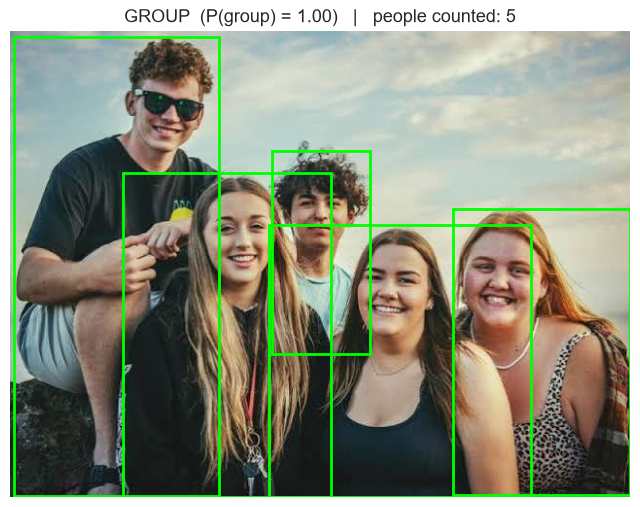

WhatsApp Image 2026-11-01 at 21.56.59.jpeg: CNN says GROUP (P(group) = 1.00); detector counted 5 person(s)


In [24]:
# Choose one or more photos from your computer (VS Code / local Jupyter).
# The notebook remains an .ipynb file; no conversion to .py is needed.
try:
    import tkinter as tk
    from tkinter import filedialog

    picker_root = tk.Tk()
    picker_root.withdraw()
    picker_root.attributes("-topmost", True)
    photo_paths = filedialog.askopenfilenames(
        title="Choose photo(s) to classify and count people",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp"),
            ("All files", "*.*"),
        ],
    )
    picker_root.destroy()

    if not photo_paths:
        print("No photos selected.")
    else:
        for photo_path in photo_paths:
            predict_photo(photo_path)
except Exception as exc:
    print("The file picker could not open:", exc)
    print("As an alternative, place images in a folder named 'my_photos' in the project root.")
    for photo_path in sorted((ROOT / "my_photos").glob("*")):
        if photo_path.suffix.lower() in EXTENSIONS:
            predict_photo(str(photo_path))


## Step 11 – Conclusions (write in your own words)

1. **Best model:** which experiment achieved the highest test F1-score and accuracy?
2. **Data augmentation:** did it help the custom CNN? Compare training and validation curves.
3. **Transfer learning:** how did pretrained ResNet50 and MobileNetV2 compare with their scratch versions?
4. **Efficiency:** compare model size, training time, and prediction speed.
5. **Errors:** inspect misclassified images and discuss possible causes.
6. **Limitations:** the dataset has two image-level classes only. It does not provide exact people counts or bounding boxes. The optional pretrained detector is a separate component and its counts are estimates.
